# Prednost domačega terena in boj za naslov v Premier League (1992–2026)

Projektna naloga pri predmetu **Uvod v programiranje** (FMF, Univerza v Ljubljani).

V zvezku analiziram podatke o vseh tekmah in končnih lestvicah angleške
Premier League od sezone 1992/93 do sezone 2025/26 (34 sezon). Podatke sem
zajel s spletne strani [FBref.com](https://fbref.com/en/comps/9/Premier-League-Stats)
(postopek je opisan v `README.md`).

Odgovoriti želim na dve skupini vprašanj:

1. **Ali domači teren vpliva na uspeh?** Kako pogosto zmagajo domači, ali dajo
   več golov, kaj se je zgodilo, ko so bile tribune med epidemijo covida-19
   prazne, in ali več gledalcev pomeni več zmag.
2. **Kdo osvaja ligo in koliko točk je za to potrebnih?** Kateri klubi so
   najpogosteje na vrhu in na dnu lestvice, koliko točk potrebuje prvak,
   koliko jih je dovolj za obstanek in kako velika je razlika med vrhom in dnom.

**Vsebina zvezka**

1. Uvoz podatkov
2. Pregled po sezonah
3. Manjkajoči podatki in preverjanje podatkov
4. Prvi vpogled: izidi vseh tekem
5. Sklop 1: Ali domači teren vpliva na uspeh?
6. Sklop 2: Kdo osvaja ligo in koliko točk je za to potrebnih?
7. Sklepne ugotovitve

Daljša koda (nalaganje, izračuni in grafi) je v datoteki `analiza_funkcije.py`,
da je zvezek pregleden.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from analiza_funkcije import (
    BARVA_DNO, BARVE_MEST, graf_tock_skozi_cas, graf_vrh_in_dno, meja_obstanka,
    oznaci_tocko, tocke_prvaka, vrh_in_dno_po_sezonah,
    delez_izidov, delez_izidov_po_sezonah, graf_golov_po_sezonah,
    graf_izidov_po_sezonah, graf_obisk_in_zmage, graf_uvrstitev_na_dnu,
    graf_uvrstitev_na_vrhu, graf_z_in_brez_gledalcev,
    graf_zmag_okoli_covida, graf_zmag_po_razredih_gledalcev, manjkajoce_vrednosti,
    nalozi_lestvice, nalozi_tekme, nastavi_slog, obisk_in_zmage_klubov,
    povezava_obiska_in_zmag, povprecni_goli_po_sezonah, pregled_po_sezonah,
    preveri_skladnost,
    primerjava_z_in_brez_gledalcev, uvrstitve_na_dnu, uvrstitve_na_vrhu,
    zmage_domacih_okoli_covida, zmage_po_razredih_gledalcev,
)

# Da pandas izpiše vse stolpce tabele, ne le prvih in zadnjih.
pd.set_option("display.max_columns", None)

# Enoten slog vseh grafov (barve, mreža, pisava).
nastavi_slog()

## 1. Uvoz podatkov

Podatki so v dveh CSV datotekah v mapi `podatki/`, ki ju ustvari `py main.py`:

- `tekme.csv` – ena vrstica za vsako odigrano tekmo,
- `lestvice.csv` – ena vrstica za vsak klub na končni lestvici vsake sezone.

In [2]:
tekme = nalozi_tekme()
lestvice = nalozi_lestvice()

print(f"Tekme:    {tekme.shape[0]} vrstic, {tekme.shape[1]} stolpcev")
print(f"Lestvice: {lestvice.shape[0]} vrstic, {lestvice.shape[1]} stolpcev")

Tekme:    13166 vrstic, 14 stolpcev
Lestvice: 686 vrstic, 16 stolpcev


### Tekme

| stolpec | pomen |
|---|---|
| `sezona` | sezona, npr. `2023-2024` |
| `krog` | številka kroga |
| `dan`, `datum`, `ura` | dan v tednu, datum in ura začetka (angleški čas) |
| `domaci`, `gostje` | domača in gostujoča ekipa |
| `goli_domaci`, `goli_gostje` | doseženi goli |
| `izid` | `D` zmaga domačih, `X` remi, `G` zmaga gostov |
| `gledalci` | število gledalcev |
| `stadion`, `sodnik` | stadion in glavni sodnik |
| `opomba` | opomba FBrefa k tekmi |

In [3]:
tekme.head()

,sezona,krog,dan,datum,ura,domaci,gostje,goli_domaci,goli_gostje,izid,gledalci,stadion,sodnik,opomba
0,1992-1993,1,Sat,1992-08-15,NaN,Arsenal,Norwich City,2,4,G,24030,Highbury,Alan Gunn,NaN
1,1992-1993,1,Sat,1992-08-15,NaN,Chelsea,Oldham Athletic,1,1,X,20699,Stamford Bridge,Jim Borrett,NaN
2,1992-1993,1,Sat,1992-08-15,NaN,Coventry City,Middlesbrough,2,1,D,12681,Highfield Road,Howard King,NaN
3,1992-1993,1,Sat,1992-08-15,NaN,Crystal Palace,Blackburn,3,3,X,17086,Selhurst Park,Roger Milford,NaN
4,1992-1993,1,Sat,1992-08-15,NaN,Everton,Sheffield Weds,1,1,X,27687,Goodison Park,Kelvin Morton,NaN


### Lestvice

| stolpec | pomen |
|---|---|
| `sezona`, `mesto`, `klub` | sezona, končno mesto in klub |
| `tekme`, `zmage`, `remiji`, `porazi` | odigrane tekme in njihovi izidi |
| `dani_goli`, `prejeti_goli`, `gol_razlika` | goli |
| `tocke`, `tocke_na_tekmo` | točke na končni lestvici (že z morebitnimi odbitki) |
| `povprecje_gledalcev` | povprečno število gledalcev na domačih tekmah |
| `najboljsi_strelec`, `goli_strelca` | najboljši strelec kluba in njegovi goli |
| `opomba` | npr. uvrstitev v evropska tekmovanja, izpad ali odbitek točk |

In [4]:
lestvice.head()

,sezona,mesto,klub,tekme,zmage,remiji,porazi,dani_goli,prejeti_goli,gol_razlika,tocke,tocke_na_tekmo,povprecje_gledalcev,najboljsi_strelec,goli_strelca,opomba
0,1992-1993,1,Manchester Utd,42,24,12,6,67,31,36,84,2.00,35132,Mark Hughes,15,→ Champions League via league finish
1,1992-1993,2,Aston Villa,42,21,11,10,57,40,17,74,1.76,29594,Dean Saunders,13,→ UEFA Cup via league finish
2,1992-1993,3,Norwich City,42,21,9,12,61,65,-4,72,1.71,16253,Mark Robins,15,→ UEFA Cup via league finish 1
3,1992-1993,4,Blackburn,42,20,11,11,68,46,22,71,1.69,16247,Alan Shearer,16,NaN
4,1992-1993,5,QPR,42,17,12,13,63,55,8,63,1.50,14999,Les Ferdinand,20,NaN


## 2. Pregled po sezonah

Vsak klub z vsakim drugim igra enkrat doma in enkrat v gosteh, zato ima
sezona z $n$ klubi $n(n-1)$ tekem. V prvih treh sezonah je bilo v ligi 22 klubov
(462 tekem), od sezone 1995/96 naprej pa 20 klubov (380 tekem).

In [5]:
pregled = pregled_po_sezonah(lestvice, tekme)
pregled

,klubi,tekme,goli,goli_na_tekmo,brez_gledalcev
sezona,,,,,
1992-1993,22,462,1222,2.65,0
1993-1994,22,462,1195,2.59,0
1994-1995,22,462,1195,2.59,0
1995-1996,20,380,988,2.60,0
1996-1997,20,380,970,2.55,0
1997-1998,20,380,1019,2.68,0
1998-1999,20,380,959,2.52,0
1999-2000,20,380,1060,2.79,0
2000-2001,20,380,992,2.61,0


In [6]:
print(f"Število sezon: {tekme['sezona'].nunique()}")
print(f"Število tekem: {len(tekme)}")
print(f"Število golov: {pregled['goli'].sum()} ({pregled['goli'].sum() / len(tekme):.2f} na tekmo)")
print(f"Različnih klubov v ligi: {lestvice['klub'].nunique()}")

# Klubi, ki so v ligi igrali vseh 34 sezon.
sezon_v_ligi = lestvice.groupby("klub").size()
print("V ligi vse sezone:", ", ".join(sezon_v_ligi[sezon_v_ligi == tekme["sezona"].nunique()].index))

Število sezon: 34
Število tekem: 13166
Število golov: 35478 (2.69 na tekmo)
Različnih klubov v ligi: 51
V ligi vse sezone: Arsenal, Chelsea, Everton, Liverpool, Manchester Utd, Tottenham


V ligi je skozi 34 sezon igral 51 različnih klubov, le šest jih ni nikoli izpadlo.
Število golov na tekmo je večino časa med 2,5 in 2,8 (najmanj 2,45 v sezoni
2006/07). Izstopa sezona 2023/24 z rekordnimi 3,28 gola na tekmo.

## 3. Manjkajoči podatki in preverjanje podatkov

Preden začnem z analizo, preverim, ali so podatki pravilni in kje manjkajo.

Tekme in lestvice sem zajel z dveh različnih strani FBrefa, zato ju lahko
primerjam: za vsak klub v vsaki sezoni iz posameznih tekem izračunam število
tekem, točke ter dane in prejete gole in jih primerjam s končno lestvico.
Spodaj so izpisani le klubi, pri katerih se kaj ne ujema.

In [7]:
neujemanja = preveri_skladnost(tekme, lestvice)
print(f"Klubov in sezon skupaj: {len(lestvice)}, neujemanj: {len(neujemanja)}")
neujemanja

Klubov in sezon skupaj: 686, neujemanj: 6


,sezona,klub,tocke,tocke_iz_tekem,dani_goli,dani_iz_tekem,prejeti_goli,prejeti_iz_tekem,opomba
0,1994-1995,Arsenal,51,51,53,52,49,49,NaN
1,1994-1995,Manchester Utd,88,88,77,77,29,28,→ UEFA Cup via league finish
2,1996-1997,Middlesbrough,39,42,51,51,60,60,"3-point deduction 3 , Relegated"
3,2009-2010,Portsmouth,19,28,34,34,66,66,"9-point deduction 3 , Relegated"
4,2023-2024,Everton,40,48,40,40,51,51,8-point deduction 1
5,2023-2024,Nottingham,32,36,49,49,67,67,4-point deduction 2


Od 686 uvrstitev se jih 680 popolnoma ujema s tekmami. Šest razlik je pojasnjenih:

- štirje klubi so dobili **odbitek točk** (Middlesbrough 1996/97, Portsmouth 2009/10,
  Everton in Nottingham Forest 2023/24), zato imajo na lestvici manj točk, kot bi jih
  dobili s tekmami (v analizi uporabljam točke z lestvice),
- pri Arsenalu in Manchester Unitedu v sezoni 1994/95 je na lestvici FBrefa en gol
  preveč; podatki o tekmah se ujemajo z uradnim izidom sezone.

Zajem podatkov je torej pravilen. Prazne vrednosti spodaj manjkajo že na FBrefu.

In [8]:
manjkajoce_vrednosti(tekme)

ura          8606
gledalci      960
opomba      13166
dtype: int64

In [9]:
manjkajoce_vrednosti(lestvice)

povprecje_gledalcev     46
opomba                 336
dtype: int64

In [10]:
# Kje manjkajo podatki o gledalcih (le sezone, kjer kaj manjka).
pregled.loc[pregled["brez_gledalcev"] > 0, ["tekme", "brez_gledalcev"]]

,tekme,brez_gledalcev
sezona,,
2007-2008,380,370
2008-2009,380,141
2009-2010,380,7
2010-2011,380,1
2019-2020,380,92
2020-2021,380,348
2022-2023,380,1


Razlage:

- **`ura`** – FBref ure začetka nima za tekme do vključno sezone 2013/14.
  Za analizo je ne potrebujem.
- **`gledalci`** – podatki manjkajo iz dveh različnih razlogov:
  - **covid-19:** v sezoni 2019/20 so vse tekme od nadaljevanja lige
    (17. 6. 2020) igrali brez gledalcev (92 tekem), v sezoni 2020/21 pa skoraj
    vse (348 tekem; na preostalih 32 je bilo dovoljenih 2.000 do 10.000 gledalcev),
  - **manjkajoči podatki:** FBref za sezono 2007/08 skoraj nima podatkov o
    gledalcih, za 2008/09 manjkajo za 141 tekem, drugje le za posamezne tekme.
    Tribune takrat niso bile prazne!
- **`povprecje_gledalcev`** – manjka pri 46 klubih. Pri 14 klubih iz sezone
  2007/08 ga FBref nima, 32 povprečij (sezone 2007/08 do 2010/11) pa sem odstranil
  pri čiščenju podatkov (`shrani_podatke.py`), ker so bila na FBrefu napačna: pri
  klubih, ki jim manjka obisk za nekaj tekem, je FBrefovo povprečje previsoko
  (npr. Chelsea 2007/08: 786.543 gledalcev, čeprav ima stadion okoli 42.000
  sedežev). Pri vseh ostalih klubih se povprečje z lestvice ujema s povprečjem,
  izračunanim iz tekem. V covidnih sezonah FBref tekme brez gledalcev šteje kot
  0 gledalcev. Zato povprečni obisk v analizi računam iz posameznih tekem in le
  za klube, ki imajo podatke za vse domače tekme.
- **`opomba`** pri tekmah je prazna pri vseh tekmah, pri lestvicah pa jo imajo
  le klubi z evropsko uvrstitvijo, izpadom ali odbitkom točk.

**Posledice za analizo:** tekme brez gledalcev zaradi covida določim po praznem
podatku *samo v sezonah 2019/20 in 2020/21*. Pri analizi vpliva števila
gledalcev tekme brez podatka izpustim (ne štejem jih kot 0 gledalcev).

## 4. Prvi vpogled: izidi vseh tekem

Za uvod pogledam, kako so se končale vse tekme skupaj.

In [11]:
imena_izidov = {"D": "zmaga domačih", "X": "remi", "G": "zmaga gostov"}
delez_izidov(tekme).rename(index=imena_izidov).round(1)

izid
zmaga domačih    45.7
remi             25.6
zmaga gostov     28.7
Name: proportion, dtype: float64

Domači zmagajo na skoraj polovici tekem (45,7 %), gostje pa le na dobri
četrtini (28,7 %). To nakazuje izrazito prednost domačega terena, ki jo podrobneje
raziščem v naslednjem razdelku.

## 5. Sklop 1: Ali domači teren vpliva na uspeh?

### 5.1 Zmage, remiji in porazi doma in v gosteh

Vsaka tekma ima domačo in gostujočo ekipo, zato zmaga domačih pomeni poraz
gostov in obratno. Za vsako sezono izračunam delež zmag domačih, remijev in
zmag gostov.

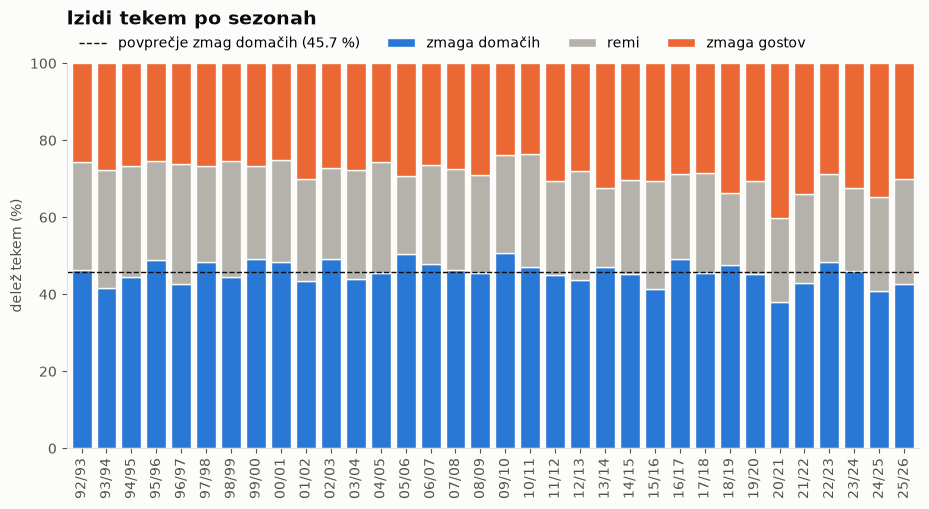

In [12]:
delezi = delez_izidov_po_sezonah(tekme)
graf_izidov_po_sezonah(delezi)
plt.show()

In [13]:
# Povprečje prvih in zadnjih desetih sezon (v odstotkih).
primerjava = pd.DataFrame({
    "prvih 10 sezon": delezi.head(10).mean(),
    "zadnjih 10 sezon": delezi.tail(10).mean(),
    "vse sezone": delez_izidov(tekme),
}).rename(index={"D": "zmaga domačih", "X": "remi", "G": "zmaga gostov"})
primerjava.round(1)

,prvih 10 sezon,zadnjih 10 sezon,vse sezone
izid,,,
zmaga domačih,45.8,44.6,45.7
remi,27.8,23.2,25.6
zmaga gostov,26.5,32.1,28.7


In [14]:
# Koliko točk v povprečju osvoji ekipa na tekmo doma in v gosteh
# (zmaga 3 točke, remi 1 točka).
tocke_doma = (3 * (tekme["izid"] == "D") + (tekme["izid"] == "X")).mean()
tocke_v_gosteh = (3 * (tekme["izid"] == "G") + (tekme["izid"] == "X")).mean()
print(f"Točke na tekmo doma:     {tocke_doma:.2f}")
print(f"Točke na tekmo v gosteh: {tocke_v_gosteh:.2f}")

Točke na tekmo doma:     1.63
Točke na tekmo v gosteh: 1.12


Domači so v **vsaki sezoni razen 2020/21** zmagali pogosteje kot gostje,
običajno na 41–51 % tekem, gostje pa na 24–35 %. Ekipa doma osvoji v povprečju
1,63 točke na tekmo, v gosteh pa le 1,12. Skozi čas se je prednost nekoliko
zmanjšala: delež zmag domačih je skoraj enak (45,8 % v prvih in 44,6 % v zadnjih
desetih sezonah), vendar je manj remijev (27,8 % → 23,2 %) in več zmag gostov
(26,5 % → 32,1 %). Izstopa sezona 2020/21, ko so bile tribune prazne: takrat so
gostje zmagali pogosteje kot domači (40,3 % proti 37,9 %).

### 5.2 Vpliv domačega terena na dane in prejete gole

Za vsako sezono izračunam, koliko golov so v povprečju na tekmo dali domači
in koliko gostje. Goli, ki jih dajo domači, so goli, ki jih prejmejo gostje,
zato graf hkrati kaže dane in prejete gole obeh strani.

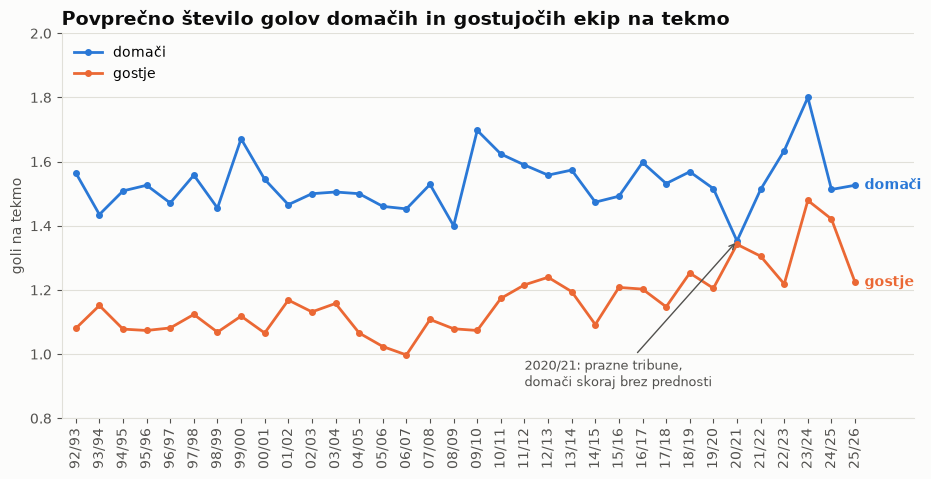

In [15]:
goli = povprecni_goli_po_sezonah(tekme)
graf_golov_po_sezonah(goli)
plt.show()

In [16]:
print(f"Povprečno na tekmo: domači {tekme['goli_domaci'].mean():.2f}, "
      f"gostje {tekme['goli_gostje'].mean():.2f} gola")
print(f"Domači dajo {tekme['goli_domaci'].mean() / tekme['goli_gostje'].mean() - 1:.0%} več golov kot gostje.")

# Sezone z največjo in najmanjšo razliko med goli domačih in gostov.
goli["razlika"].round(2).sort_values().iloc[[0, 1, -1]]

Povprečno na tekmo: domači 1.53, gostje 1.16 gola
Domači dajo 32% več golov kot gostje.


sezona
2020-2021    0.01
2024-2025    0.09
2009-2010    0.62
Name: razlika, dtype: float64

Domači dajo v povprečju 1,53 gola na tekmo, gostje pa 1,16, torej približno
**32 % več**. Črta domačih je v vseh sezonah nad črto gostov, vendar se razlika
zmanjšuje: v prvih desetih sezonah je bila v povprečju 0,42 gola na tekmo, v
zadnjih desetih le še 0,28. Gostje so v zadnjem desetletju postali nevarnejši
(1,10 → 1,28 gola na tekmo), domači pa so ostali na skoraj enaki ravni.
V sezoni 2020/21 brez gledalcev je razlika skoraj izginila (0,01 gola), kar
nakazuje, da del prednosti domačega terena prinašajo prav gledalci. To podrobneje
preverim v naslednjem razdelku.

### 5.3 Prazne tribune (covid-19)

Zaradi epidemije covida-19 so od 17. 6. 2020 (nadaljevanje sezone 2019/20) do
konca sezone 2020/21 tekme igrali brez gledalcev; le na 32 tekmah v sezoni 2020/21
je bilo dovoljenih 2.000 do 10.000 gledalcev. To je skoraj naraven poskus: kaj se
zgodi s prednostjo domačih, ko ni navijačev?

Tekme brez gledalcev določim po praznem podatku o gledalcih, a **le v sezonah
2019/20 in 2020/21** (drugod prazen podatek pomeni, da ga FBref nima).

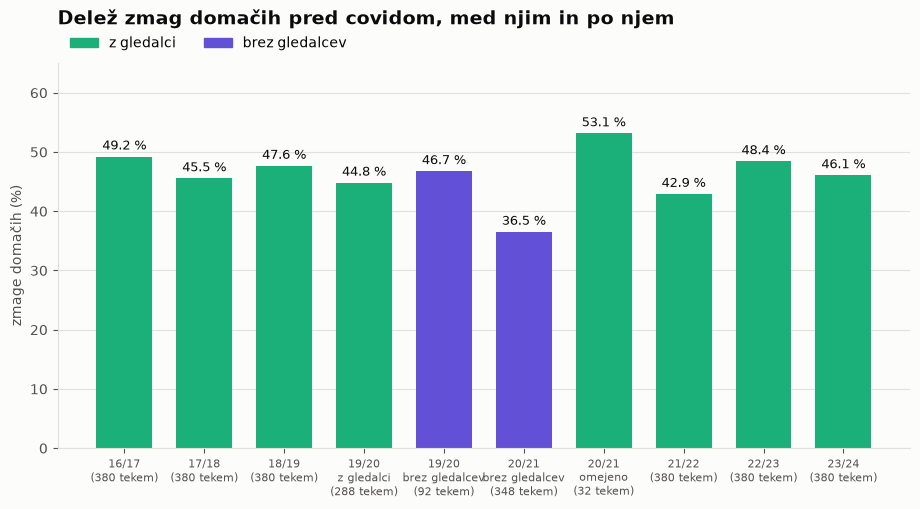

In [17]:
obdobja = zmage_domacih_okoli_covida(tekme)
graf_zmag_okoli_covida(obdobja)
plt.show()

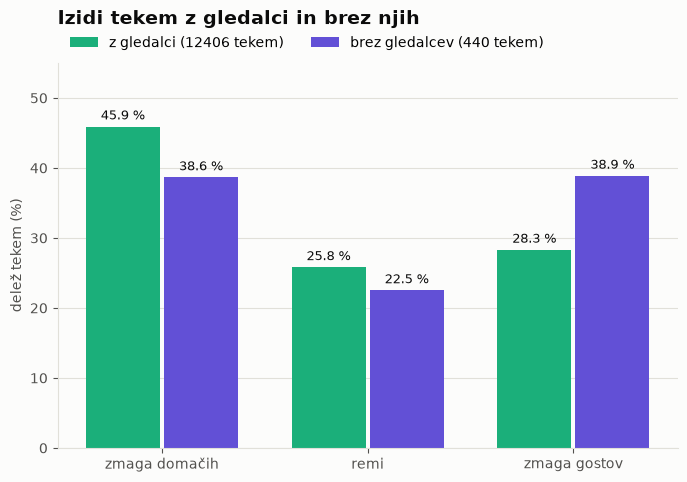

,z gledalci,brez gledalcev
tekme,12406.00,440.00
zmaga domačih (%),45.91,38.64
remi (%),25.80,22.50
zmaga gostov (%),28.29,38.86
goli domačih na tekmo,1.54,1.37
goli gostov na tekmo,1.16,1.32
točke domačih na tekmo,1.64,1.38
točke gostov na tekmo,1.11,1.39


In [18]:
primerjava_covid = primerjava_z_in_brez_gledalcev(tekme)
graf_z_in_brez_gledalcev(primerjava_covid)
plt.show()

primerjava_covid.round(2)

Na 440 tekmah brez gledalcev so domači zmagali na 38,6 % tekem, kar je
7 odstotnih točk manj kot sicer (45,9 %). Gostje so takrat zmagovali enako pogosto
kot domači (38,9 %). Domači so dali manj golov (1,37 namesto 1,54), gostje več
(1,32 namesto 1,16), in osvojili so celo nekoliko manj točk kot gostje
(1,38 proti 1,39 na tekmo). **Brez gledalcev je prednost domačega terena praktično
izginila.**

Zanimivo je, da se je to pokazalo šele v sezoni 2020/21 (36,5 % zmag domačih).
Na 92 tekmah brez gledalcev ob koncu sezone 2019/20 je bil delež zmag domačih
običajen (46,7 %). Vzorec 92 tekem je majhen, zato iz njega ne morem sklepati
veliko; vpliv praznih tribun se jasno pokaže šele v celi sezoni 2020/21.
Po vrnitvi gledalcev se je delež zmag domačih spet vrnil na običajno raven.

### 5.4 Ali več gledalcev pomeni več zmag?

Prazne tribune so pokazale, da gledalci *so* pomembni. Ali pa velja tudi, da
več gledalcev pomeni več zmag? Najprej tekme (brez covidnih sezon in tekem brez
podatka) razdelim v razrede po številu gledalcev.

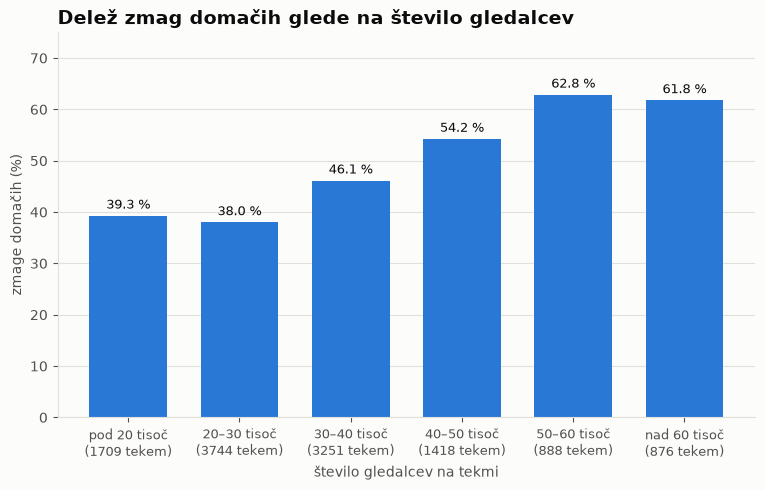

In [19]:
razredi = zmage_po_razredih_gledalcev(tekme)
graf_zmag_po_razredih_gledalcev(razredi)
plt.show()

Na tekmah z več kot 50.000 gledalci domači zmagajo na več kot 60 % tekem, pri
manj kot 30.000 gledalcih pa le na okoli 38 %. Vendar to še ne pomeni, da gledalci
prinašajo zmage: velike stadione imajo večinoma najmočnejši klubi, ki zmagujejo tudi
v gosteh.

Zato pogledam še vsak klub v vsaki sezoni posebej: povprečni obisk (izračunan iz
tekem) in delež zmag doma.

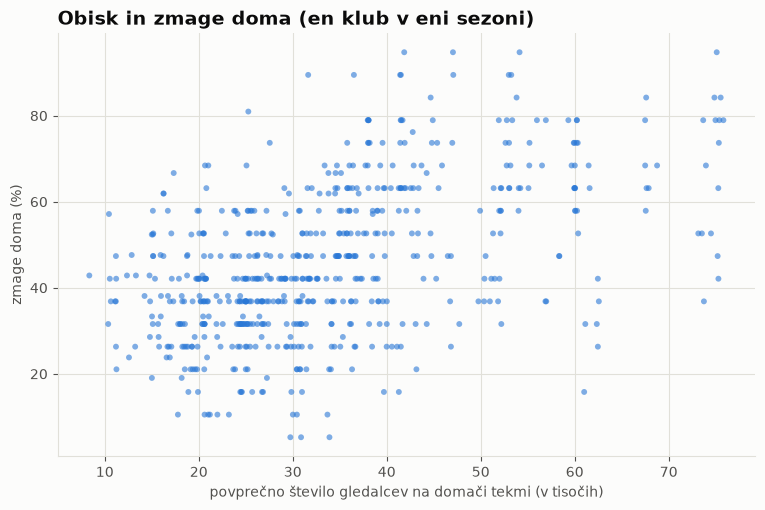

Klubov in sezon: 598
Korelacija med obiskom in zmagami doma (vsi klubi):  0.51
Korelacija znotraj klubov (klub primerjan sam s seboj): 0.09


In [20]:
obisk = obisk_in_zmage_klubov(tekme)
graf_obisk_in_zmage(obisk)
plt.show()

povezava = povezava_obiska_in_zmag(obisk)
print(f"Klubov in sezon: {len(obisk)}")
print(f"Korelacija med obiskom in zmagami doma (vsi klubi):  {povezava['vsi klubi']:.2f}")
print(f"Korelacija znotraj klubov (klub primerjan sam s seboj): {povezava['znotraj klubov']:.2f}")

Med vsemi klubi je povezava zmerna (korelacija 0,51): klubi z večjim obiskom
pogosteje zmagujejo doma. Ko pa vsak klub primerjam samega s seboj (ali je v
sezonah z večjim obiskom zmagoval pogosteje kot v sezonah z manjšim), povezave
skoraj ni (0,09). Večji obisk torej predvsem **spremlja** močne klube in sam po
sebi ne prinaša več zmag.

**Sklep sklopa 1:** domači teren prinaša jasno prednost (45,7 % zmag doma proti
28,7 % v gosteh), ki se sicer počasi manjša. Prazne tribune med covidom kažejo,
da velik del te prednosti prinaša prisotnost gledalcev, njihovo število pa nima
pomembnega vpliva.

## 6. Sklop 2: Kdo osvaja ligo in koliko točk je za to potrebnih?

V drugem sklopu uporabljam končne lestvice. Pri primerjavi skozi čas je treba
upoštevati, da je bilo v prvih treh sezonah v ligi 22 klubov (42 tekem), kasneje
pa 20 klubov (38 tekem).

### 6.1 Kdo najpogosteje konča na vrhu lestvice?

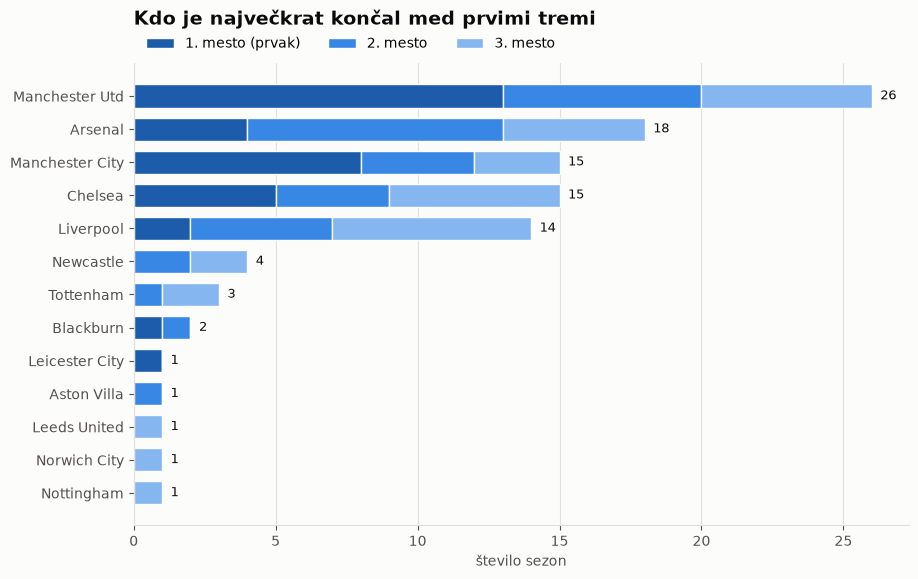

mesto,1,2,3,skupaj
klub,,,,
Manchester Utd,13,7,6,26
Arsenal,4,9,5,18
Manchester City,8,4,3,15
Chelsea,5,4,6,15
Liverpool,2,5,7,14
Newcastle,0,2,2,4
Tottenham,0,1,2,3
Blackburn,1,1,0,2
Leicester City,1,0,0,1


In [21]:
vrh = uvrstitve_na_vrhu(lestvice)
graf_uvrstitev_na_vrhu(vrh)
plt.show()

vrh

In [22]:
velika_peterica = ["Manchester Utd", "Arsenal", "Manchester City", "Chelsea", "Liverpool"]
mest_velike_peterice = vrh.loc[velika_peterica, "skupaj"].sum()
print(f"Različnih prvakov: {(vrh[1] > 0).sum()}")
print(f"Različnih klubov med prvimi tremi: {len(vrh)}")
print(f"Mest med prvimi tremi, ki jih je osvojila velika peterica: "
      f"{mest_velike_peterice} od {vrh['skupaj'].sum()} ({mest_velike_peterice / vrh['skupaj'].sum():.0%})")

Različnih prvakov: 7
Različnih klubov med prvimi tremi: 13
Mest med prvimi tremi, ki jih je osvojila velika peterica: 88 od 102 (86%)


Vrh lestvice je izjemno zaprt. V 34 sezonah je bilo le **sedem različnih prvakov**,
med prvimi tremi pa je končalo le 13 klubov. Pet klubov (Manchester United, Arsenal,
Manchester City, Chelsea in Liverpool) je osvojilo 88 od 102 mest med prvimi tremi
(86 %). Manchester United je naslov osvojil 13-krat, zadnjič v sezoni 2012/13; v
zadnjih desetih sezonah pa je prevladoval Manchester City s šestimi naslovi.
Izjemi sta Blackburn (1994/95) in predvsem Leicester City (2015/16).

### 6.2 Kdo najpogosteje konča na dnu lestvice?

Kot dno štejem zadnja tri mesta lestvice: v sezonah z 22 klubi 20.–22. mesto,
kasneje 18.–20. mesto.

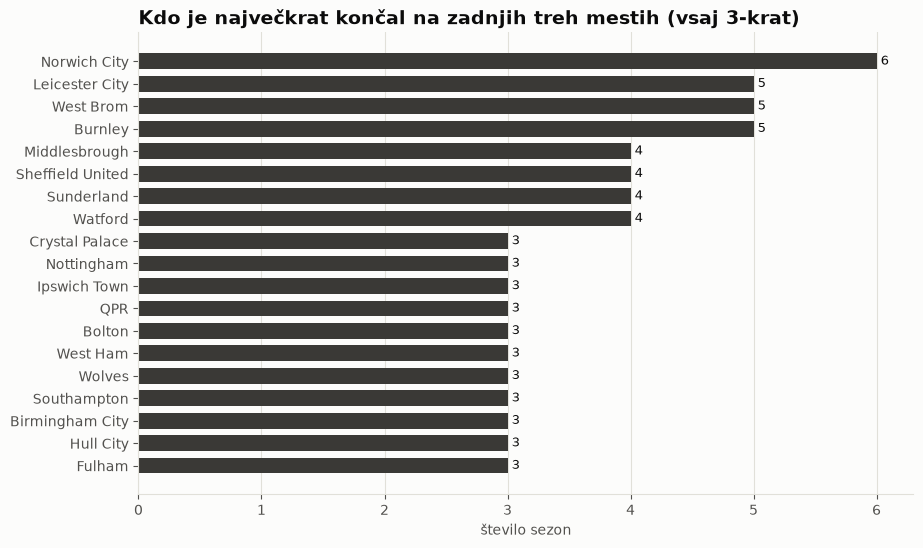

Različnih klubov na zadnjih treh mestih: 43
Prvaki, ki so kdaj končali na zadnjih treh mestih: {'Manchester City': 2, 'Blackburn': 2, 'Leicester City': 5}


In [23]:
dno = uvrstitve_na_dnu(lestvice)
graf_uvrstitev_na_dnu(dno)
plt.show()

print(f"Različnih klubov na zadnjih treh mestih: {len(dno)}")
print("Prvaki, ki so kdaj končali na zadnjih treh mestih:",
      {klub: int(dno[klub]) for klub in vrh[vrh[1] > 0].index if klub in dno.index})

Dno lestvice je precej bolj raznoliko kot vrh: na zadnjih treh mestih je končalo
**43 različnih klubov**, noben pa več kot šestkrat (Norwich City). Gre večinoma za
klube, ki se selijo med Premier League in drugo ligo (West Brom, Burnley, Watford,
Sheffield United …). Na dnu so končali tudi trije prvaki: Manchester City dvakrat pred
svojimi naslovi (1995/96 in 2000/01), Blackburn dvakrat po naslovu iz leta 1994/95
(1998/99 in 2011/12), najbolj presenetljiv pa je Leicester City, ki je bil petkrat
med zadnjimi tremi (tudi v sezonah 2022/23 in 2024/25), v sezoni 2015/16 pa prvak.

### 6.3 Koliko točk potrebuje prvak?

Ker so imele prve tri sezone 42 tekem, točke vseh sezon preračunam na 38 tekem
(točke na tekmo × 38). Tako so sezone med seboj primerljive.

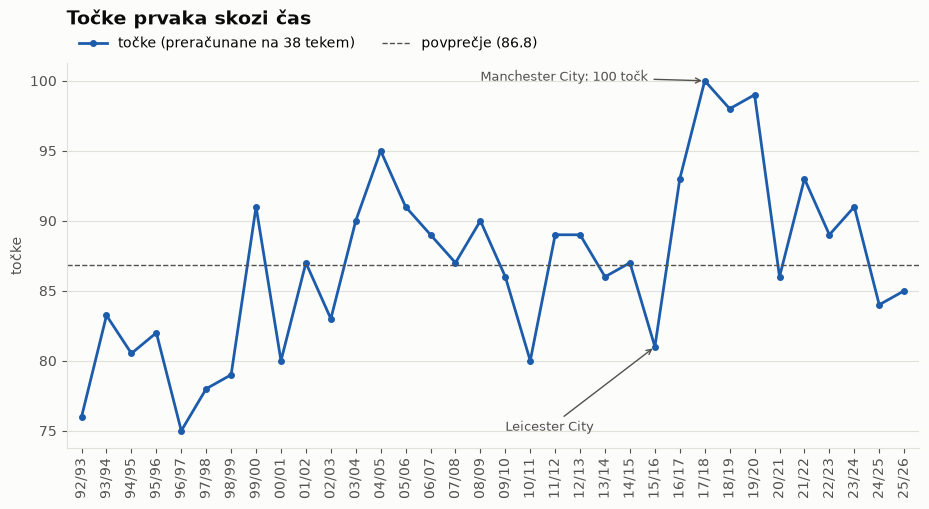

Prvih 10 sezon:   povprečno 81.2 točk
Zadnjih 10 sezon: povprečno 91.8 točk


In [24]:
prvaki = tocke_prvaka(lestvice)
ax = graf_tock_skozi_cas(prvaki["tocke_38"], BARVE_MEST[1], "Točke prvaka skozi čas", "povprečje")
oznaci_tocko(ax, prvaki["tocke_38"], "2017-2018", "Manchester City: 100 točk", (-9, 0))
oznaci_tocko(ax, prvaki["tocke_38"], "2015-2016", "Leicester City", (-6, -6))
plt.show()

print(f"Prvih 10 sezon:   povprečno {prvaki['tocke_38'].head(10).mean():.1f} točk")
print(f"Zadnjih 10 sezon: povprečno {prvaki['tocke_38'].tail(10).mean():.1f} točk")

Prvak v povprečju zbere 87 točk, a se je meja naslova skozi čas dvignila:
v prvih desetih sezonah je bilo povprečno dovolj 81 točk (Manchester United je
leta 1996/97 postal prvak s 75 točkami), v zadnjih desetih pa jih je prvak zbral
92. Med sezonama 2017/18 in 2019/20 sta Manchester City in Liverpool zbrala
98–100 točk, kar je rekord lige. Leicester City je leta 2015/16 postal prvak s
81 točkami, kar je za sodobno ligo malo.

### 6.4 Koliko točk je dovolj za obstanek?

Za vsako sezono poiščem najslabši klub, ki je obstal v ligi (mesto tik nad
izpadlimi). Število izpadlih preberem iz opomb na lestvici: običajno so izpadli
trije klubi, v sezoni 1994/95 pa štirje, ker se je liga zmanjšala na 20 klubov.
Točke so take, kot so na končni lestvici, torej že z morebitnimi odbitki.

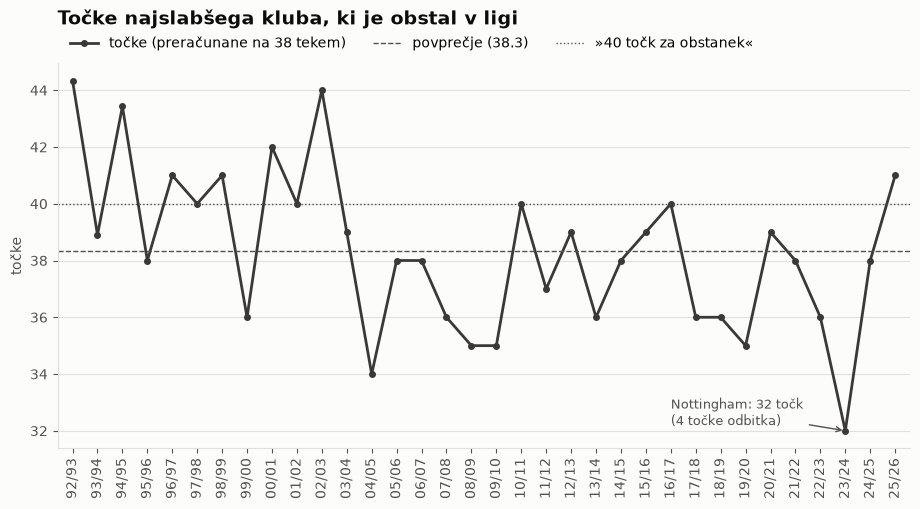

Sezon, ko je bilo za obstanek potrebnih vsaj 40 točk: 11 od 34
Prvih 10 sezon: 40.5, zadnjih 10 sezon: 37.1 točk


,izpadel,tocke_izpadlega
sezona,,
1996-1997,Sunderland,40
1997-1998,Bolton,40
2002-2003,West Ham,42


In [25]:
obstanek = meja_obstanka(lestvice)
ax = graf_tock_skozi_cas(obstanek["tocke_38"], BARVA_DNO,
                         "Točke najslabšega kluba, ki je obstal v ligi", "povprečje",
                         referenca=(40, "»40 točk za obstanek«"))
oznaci_tocko(ax, obstanek["tocke_38"], "2023-2024", "Nottingham: 32 točk\n(4 točke odbitka)", (-7, 0.2))
plt.show()

print(f"Sezon, ko je bilo za obstanek potrebnih vsaj 40 točk: "
      f"{(obstanek['tocke_38'].round() >= 40).sum()} od {len(obstanek)}")
print(f"Prvih 10 sezon: {obstanek['tocke_38'].head(10).mean():.1f}, "
      f"zadnjih 10 sezon: {obstanek['tocke_38'].tail(10).mean():.1f} točk")

# Izpadli klubi, ki so imeli vsaj 40 točk (le sezone z 38 tekmami).
obstanek.loc[(obstanek["tocke_izpadlega"] >= 40) & (lestvice.groupby("sezona")["tekme"].first() == 38),
             ["izpadel", "tocke_izpadlega"]]

V nogometu velja pravilo, da je za obstanek potrebnih 40 točk. Podatki kažejo,
da je bilo v povprečju dovolj **38 točk**, 40 ali več pa jih je bilo potrebnih le v
11 od 34 sezon. Meja obstanka se je znižala: v prvih desetih sezonah je bila
40,5 točke, v zadnjih desetih 37,1. Nottingham Forest je leta 2023/24 obstal z le
32 točkami (po odbitku štirih točk). Pravilo pa ne zagotavlja varnosti: trije klubi
so izpadli kljub 40 ali več točkam, West Ham leta 2002/03 celo z 42.

### 6.5 Kako velika je razlika med vrhom in dnom?

Za vsako sezono izračunam povprečne točke in povprečno gol razliko prvih treh in
zadnjih treh klubov, oboje na tekmo (da so sezone z 42 in 38 tekmami primerljive).

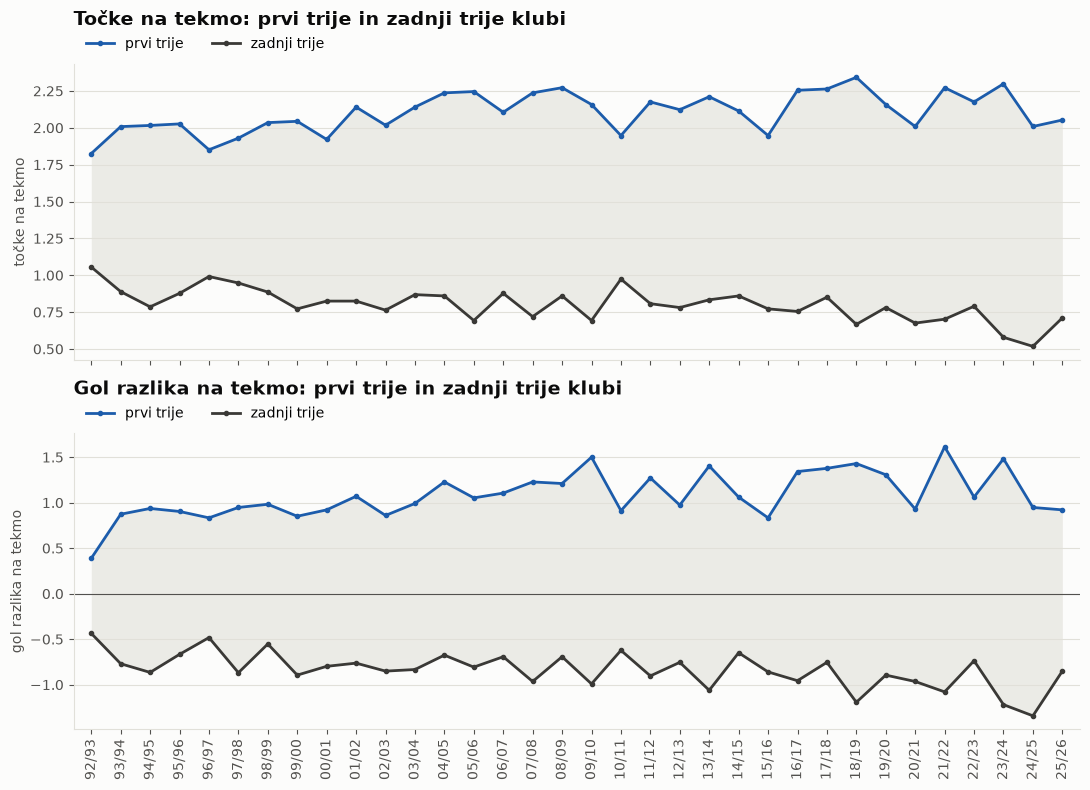

,prvih 10 sezon,zadnjih 10 sezon
tocke_vrh,1.98,2.18
tocke_dno,0.89,0.70
gol_razlika_vrh,0.87,1.24
gol_razlika_dno,-0.71,-1.00
razlika_tock,1.09,1.48
razlika_gol_razlike,1.58,2.24


In [26]:
vrh_dno = vrh_in_dno_po_sezonah(lestvice)
graf_vrh_in_dno(vrh_dno)
plt.show()

primerjava_obdobij = pd.DataFrame({
    "prvih 10 sezon": vrh_dno.head(10).mean(),
    "zadnjih 10 sezon": vrh_dno.tail(10).mean(),
})
primerjava_obdobij.round(2)

Razlika med vrhom in dnom lestvice se veča. Prvi trije klubi so v prvih desetih
sezonah zbrali povprečno 1,98 točke na tekmo, v zadnjih desetih 2,18; zadnji trije
pa so padli z 0,89 na 0,70 točke na tekmo. Razlika v točkah na tekmo je tako zrasla
z 1,09 na 1,48, razlika v gol razliki pa z 1,58 na 2,24 gola na tekmo. Najmočnejši
klubi so torej vse močnejši, najšibkejši pa vse šibkejši, zato so tudi točke prvaka
vse višje, točke za obstanek pa vse nižje.

**Sklep sklopa 2:** ligo osvaja majhna skupina klubov (sedem prvakov v 34 sezonah,
86 % mest med prvimi tremi za pet klubov), medtem ko se na dnu vrsti veliko različnih
klubov. Prvak danes potrebuje okoli 90 točk, za obstanek pa običajno zadošča manj kot
40, saj se razlika med vrhom in dnom lige povečuje.

## 7. Sklepne ugotovitve

### Sklop 1: Ali domači teren vpliva na uspeh?

- **Da.** Domači so zmagali na 45,7 % od 13.166 tekem, gostje na 28,7 %. Ekipa doma
  osvoji povprečno 1,63 točke na tekmo, v gosteh 1,12, in da približno 32 % več golov.
- **Prednost se počasi manjša.** Delež zmag domačih je skoraj enak kot v 90. letih,
  vendar je manj remijev in več zmag gostov; razlika v golih med domačimi in gosti
  je padla z 0,42 na 0,28 gola na tekmo.
- **Gledalci so pomemben del prednosti.** Na 440 tekmah brez gledalcev med covidom
  so domači zmagali le na 38,6 % tekem, enako pogosto kot gostje, in osvojili celo
  nekoliko manj točk.
- **Število gledalcev pa ni odločilno.** Na tekmah z veliko gledalci domači res
  zmagujejo pogosteje, vendar zato, ker imajo velike stadione močni klubi. Ko klub
  primerjam samega s seboj, povezave med obiskom in zmagami skoraj ni (korelacija 0,09).

### Sklop 2: Kdo osvaja ligo in koliko točk je za to potrebnih?

- **Vrh je zaprt.** V 34 sezonah je bilo le sedem prvakov; pet klubov je osvojilo
  86 % vseh mest med prvimi tremi. Manchester United je prvak 13-krat, Manchester City
  pa je osvojil šest od zadnjih desetih naslovov.
- **Dno je odprto.** Na zadnjih treh mestih je končalo 43 različnih klubov.
- **Prvak potrebuje vse več točk:** v prvih desetih sezonah povprečno 81, v zadnjih
  desetih 92 (rekord je 100 točk).
- **Za obstanek je potrebnih vse manj točk:** povprečno 38, v zadnjih desetih
  sezonah 37. Pravilo »40 točk« je veljalo le v 11 od 34 sezon.
- **Liga je vse bolj neenakomerna:** razlika med prvimi tremi in zadnjimi tremi klubi
  je zrasla z 1,09 na 1,48 točke na tekmo.

### Omejitve analize

- Podatki o gledalcih manjkajo za sezoni 2007/08 in 2008/09 ter za posamezne tekme,
  povprečni obisk na lestvicah FBrefa pa je za ti dve sezoni napačen, zato sem ga
  računal iz tekem.
- Prazne tribune so bile le v dveh sezonah (440 tekem), ki sta bili tudi sicer
  nenavadni (zgoščen razpored, kratke priprave), zato vsega upada prednosti domačih
  ne morem pripisati le gledalcem.
- Korelacija ne pomeni vzročnosti: iz podatkov vidim povezave, ne pa njihovih vzrokov.
- Točke iz prvih treh sezon (42 tekem) so preračunane na 38 tekem, kar je približek.